In [1]:
import urllib.request
import urllib.parse
import json
import requests
import time
import pandas as pd
import matplotlib.pyplot as plt
import os
from datetime import datetime
from zoneinfo import ZoneInfo




In [2]:

name = "Dresden"

# 1. build the query string (encodes special characters)
query = urllib.parse.urlencode({"name": name, "count": 5})
url = "https://geocoding-api.open-meteo.com/v1/search?" + query
print(url)

# 2. send the request and read the answer (bytes)
response = urllib.request.urlopen(url, timeout=10)
raw = response.read()

# 3. bytes -> text -> Python dictionary
data = json.loads(raw.decode("utf-8"))

# 4. use it
first = data["results"][0]
print(first["name"], first["country"], first["latitude"], first["longitude"])

https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=5
Dresden Germany 51.05089 13.73832


In [3]:

response = requests.get(
    "https://geocoding-api.open-meteo.com/v1/search",
    params={"name": "Dresden", "count": 5},
    timeout=10,
)
data = response.json()
first = data["results"][0]
print(first["name"], first["country"], first["latitude"], first["longitude"])

Dresden Germany 51.05089 13.73832


In [4]:

start = time.perf_counter()
r = requests.get("https://geocoding-api.open-meteo.com/v1/search",
                 params={"name": "Dresden"}, timeout=10)
elapsed = time.perf_counter() - start

print("Status:", r.status_code)                 # 200 = OK
print("Content-Type:", r.headers["Content-Type"])
print("Time:", round(elapsed, 3), "seconds")

Status: 200
Content-Type: application/json; charset=utf-8
Time: 0.876 seconds


In [5]:
geocode_url = 'https://geocoding-api.open-meteo.com/v1/search'


Error handling and request helper.

In [6]:
class WeatherAPIError(Exception):
    """Raised when talking to a weather API fails for good."""

In [7]:

def request_json(url, params=None, headers=None, timeout=10, max_retries=3, backoff=0.5):
    """GET a URL and return its JSON, retrying temporary failures.

    Waits backoff * 2**attempt seconds between tries (0.5s, 1s, 2s...).
    Raises WeatherAPIError if every attempt fails.
    """
    last_error = None   # remember the most recent problem

    # range(max_retries + 1) -> 4 attempts in total: the first try + 3 retries
    for attempt in range(max_retries + 1):
        try:
            response = requests.get(url, params=params, headers=headers, timeout=timeout)
            response.raise_for_status()      # 4xx/5xx -> raises HTTPError
            return response.json()           # success: leave the function here

        except (requests.exceptions.ConnectionError,
                requests.exceptions.Timeout) as exc:
            last_error = exc                 # temporary problem: try again

        except requests.exceptions.HTTPError as exc:
            status = exc.response.status_code
            if status >= 500 or status == 429:
                last_error = exc             # server trouble / rate limit: try again
            else:
                # 400, 404...: OUR mistake, retrying won't help, stop immediately
                raise WeatherAPIError(f"HTTP {status}: request rejected") from exc

        except ValueError as exc:            # reply wasn't valid JSON
            raise WeatherAPIError("Reply was not valid JSON") from exc

        # We only reach here if the attempt failed and is retryable
        if attempt < max_retries:
            wait = backoff * (2 ** attempt)  # 0.5, 1.0, 2.0 ...
            print(f"Attempt {attempt + 1} failed, waiting {wait}s")
            time.sleep(wait)

    # Loop finished: every attempt failed
    raise WeatherAPIError(f"Gave up after {max_retries + 1} attempts: {last_error}") from last_error

In [8]:
def parse_geocode(data):
    """Return the list of candidate places from geocoding JSON (no network)."""
    if "results" not in data:
        raise WeatherAPIError("No place found with that name")
    return data["results"]


def geocode(name):
    """Return a list of candidate places for a city name."""
    if not name.strip():
        raise WeatherAPIError("City name is empty")
    data = request_json(geocode_url, params={"name": name, "count": 10, "language": "en"})
    return parse_geocode(data)

In [9]:
try:
    places = geocode("zzzqqqxxwwvv")
except WeatherAPIError as exc:
    print("Handled cleanly:", exc)

Handled cleanly: No place found with that name


In [10]:
candidates = geocode('Springfield')

if len(candidates) == 0:
    print("No place found with that name ")
else:
    for i, place in enumerate(candidates):
        print(i,place['name'], place.get('admin1',''), place['country'])

0 Springfield Missouri United States
1 Springfield Illinois United States
2 Springfield Massachusetts United States
3 Springfield Ohio United States
4 Springfield Tennessee United States
5 Palmyra Missouri United States
6 Jackson Minnesota United States
7 Springfield Kentucky United States
8 Springfield Georgia United States
9 Springfield Colorado United States


In [11]:
choice = int(input('pick a number:  '))
place = candidates[choice]
latitude = place['latitude']
longitude = place['longitude']
print('using:', place['name'], latitude, longitude)


pick a number:   0


using: Springfield 37.21533 -93.29824


B2 get forecast

In [12]:
forecast_url = 'https://api.open-meteo.com/v1/forecast'

def get_forecast(lat, lon, days=7):
    """Return the daily forecast JSON for the given coordinates."""
    if not -90 <= lat <= 90:
        raise WeatherAPIError(f"Latitude {lat} is outside -90..90")

    params = {
        "latitude": lat, "longitude": lon,
        "daily": "weather_code,temperature_2m_max,temperature_2m_min,"
                 "precipitation_sum,wind_speed_10m_max",
        "timezone": "auto", "forecast_days": days,
    }
    return request_json(forecast_url, params=params)

"""def get_forecast(latitude,longitude, days=7):
       Returns the daily forecast JSON as a dictionary for the given coordinates.
    daily lists the variables we want. timzone 'auto'makes us use the local time in question foreast daysis how many days ahead
    params = {'latitude': latitude,
             'longitude': longitude,
              'daily': 'weather_code,temperature_2m_max,temperature_2m_min,''precipitation_sum,wind_speed_10m_max',
              'timezone': 'auto',
              'forecast_days': days,
                          
             }
    response = requests.get(forecast_url, params=params, timeout=10)
    return response.json"""
forecast = get_forecast(latitude,longitude,5)
print(forecast['daily'])

{'time': ['2026-10-22', '2026-10-23', '2026-10-24', '2026-10-25', '2026-10-26'], 'weather_code': [3, 3, 3, 3, 3], 'temperature_2m_max': [23.9, 24.7, 24.9, 24.6, 23.3], 'temperature_2m_min': [8.7, 11.7, 13.4, 14.6, 13.5], 'precipitation_sum': [0.0, 0.0, 0.0, 0.0, 0.0], 'wind_speed_10m_max': [9.7, 15.7, 15.2, 12.0, 11.2]}


In [13]:
daily = forecast['daily']
units = forecast['daily_units']

print(units)

{'time': 'iso8601', 'weather_code': 'wmo code', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h'}


In [14]:
WMO_CODES = {
    0: "Clear sky", 1: "Mainly clear", 2: "Partly cloudy", 3: "Overcast",
    45: "Fog", 48: "Depositing rime fog",
    51: "Light drizzle", 53: "Moderate drizzle", 55: "Dense drizzle",
    56: "Light freezing drizzle", 57: "Dense freezing drizzle",
    61: "Slight rain", 63: "Moderate rain", 65: "Heavy rain",
    66: "Light freezing rain", 67: "Heavy freezing rain",
    71: "Slight snow fall", 73: "Moderate snow fall", 75: "Heavy snow fall",
    77: "Snow grains",
    80: "Slight rain showers", 81: "Moderate rain showers", 82: "Violent rain showers",
    85: "Slight snow showers", 86: "Heavy snow showers",
    95: "Thunderstorm", 96: "Thunderstorm with slight hail",
    99: "Thunderstorm with heavy hail",
}

print(WMO_CODES[61])                        # Slight rain
print(WMO_CODES.get(1234, "Unknown code"))  # .get avoids a KeyError for missing keys

Slight rain
Unknown code


In [15]:
df = pd.DataFrame({
    # convert the date strings to real dates
    "Date": pd.to_datetime(daily["time"]),

    # decode each code into words (list comprehension, explained below)
    "Weather": [WMO_CODES.get(code, "Unknown") for code in daily["weather_code"]],

    # unit goes inside the column name, taken from the API's own units block
    f"Max temp ({units['temperature_2m_max']})": daily["temperature_2m_max"],
    f"Min temp ({units['temperature_2m_min']})": daily["temperature_2m_min"],
    f"Precipitation ({units['precipitation_sum']})": daily["precipitation_sum"],
    f"Max wind ({units['wind_speed_10m_max']})": daily["wind_speed_10m_max"],
})

print(df)

        Date   Weather  Max temp (°C)  Min temp (°C)  Precipitation (mm)  \
0 2026-10-22  Overcast           23.9            8.7                 0.0   
1 2026-10-23  Overcast           24.7           11.7                 0.0   
2 2026-10-24  Overcast           24.9           13.4                 0.0   
3 2026-10-25  Overcast           24.6           14.6                 0.0   
4 2026-10-26  Overcast           23.3           13.5                 0.0   

   Max wind (km/h)  
0              9.7  
1             15.7  
2             15.2  
3             12.0  
4             11.2  


In [16]:
def forecast_to_dataframe(payload):
    """Convert the Open-Meteo forecast JSON (a dict) into a pandas DataFrame."""
    daily = payload["daily"]
    units = payload["daily_units"]

    return pd.DataFrame({
        "Date": pd.to_datetime(daily["time"]),
        "Weather": [WMO_CODES.get(c, "Unknown") for c in daily["weather_code"]],
        f"Max temp ({units['temperature_2m_max']})": daily["temperature_2m_max"],
        f"Min temp ({units['temperature_2m_min']})": daily["temperature_2m_min"],
        f"Precipitation ({units['precipitation_sum']})": daily["precipitation_sum"],
        f"Max wind ({units['wind_speed_10m_max']})": daily["wind_speed_10m_max"],
    })

df = forecast_to_dataframe(forecast)
print(df.to_string(index=False))    # index=False hides the 0,1,2... row numbers

      Date  Weather  Max temp (°C)  Min temp (°C)  Precipitation (mm)  Max wind (km/h)
2026-10-22 Overcast           23.9            8.7                 0.0              9.7
2026-10-23 Overcast           24.7           11.7                 0.0             15.7
2026-10-24 Overcast           24.9           13.4                 0.0             15.2
2026-10-25 Overcast           24.6           14.6                 0.0             12.0
2026-10-26 Overcast           23.3           13.5                 0.0             11.2


In [17]:
tmax = 'Max temp (°C)'
tmin = 'Min temp (°C)'
rain = 'Precipitation (mm)'
wind = 'Max wind (km/h)'


In [18]:
# idxmax() gives the ROW NUMBER of the largest value in a column.
# df.loc[row] then fetches that whole row.
hottest = df.loc[df[tmax].idxmax()]
coldest = df.loc[df[tmin].idxmin()]
wettest = df.loc[df[rain].idxmax()]

# Count days with more than 0.1 mm of rain.
# (df[rain] > 0.1) makes True/False per row, and sum() counts the Trues.
wet_days = (df[rain] > 0.1).sum()

print(f"Forecast for {place['name']}, {place['country']}")
print(f"Warmest day : {hottest['Date']:%A %d %b}, high of {hottest[tmax]} °C")
print(f"Coldest night: {coldest['Date']:%A %d %b}, low of {coldest[tmin]} °C")
print(f"Rainy days  : {wet_days}, wettest is {wettest['Date']:%A %d %b} ({wettest[rain]} mm)")
print(f"Windiest    : up to {df[wind].max()} km/h")
print("Source: Open-Meteo.com")

Forecast for Springfield, United States
Warmest day : Saturday 24 Oct, high of 24.9 °C
Coldest night: Thursday 22 Oct, low of 8.7 °C
Rainy days  : 0, wettest is Thursday 22 Oct (0.0 mm)
Windiest    : up to 15.7 km/h
Source: Open-Meteo.com


In [19]:
# Work on a copy so the original df keeps real dates.
table = df.copy()

# Turn the date into readable text, e.g. "Mon 2026-10-12"
table["Date"] = table["Date"].dt.strftime("%a %Y-%m-%d")

# index=False hides the 0,1,2... row numbers
print(table.to_string(index=False))

          Date  Weather  Max temp (°C)  Min temp (°C)  Precipitation (mm)  Max wind (km/h)
Thu 2026-10-22 Overcast           23.9            8.7                 0.0              9.7
Fri 2026-10-23 Overcast           24.7           11.7                 0.0             15.7
Sat 2026-10-24 Overcast           24.9           13.4                 0.0             15.2
Sun 2026-10-25 Overcast           24.6           14.6                 0.0             12.0
Mon 2026-10-26 Overcast           23.3           13.5                 0.0             11.2


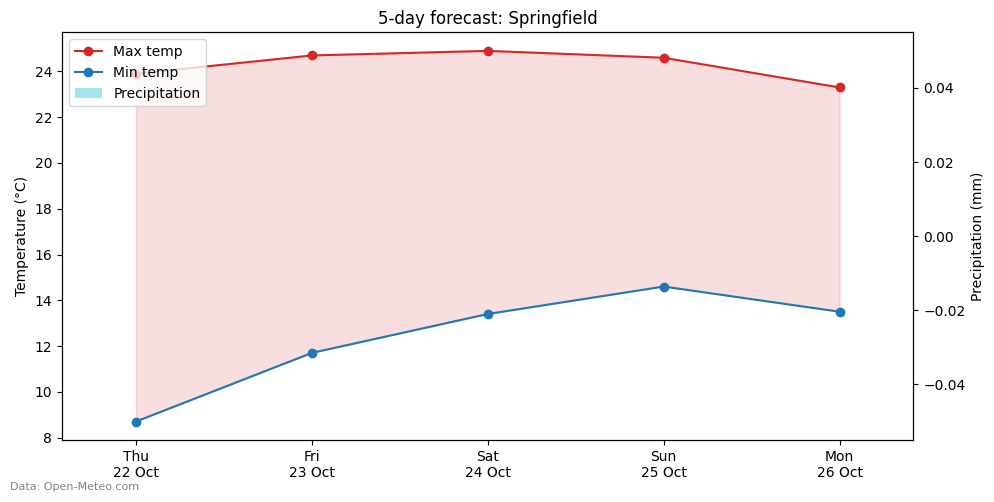

In [20]:

# x positions 0,1,2,... one per day
x = list(range(len(df)))

# fig = the whole picture, ax = the main drawing area
fig, ax = plt.subplots(figsize=(10, 5))

# Temperature: two lines with the area between them shaded
ax.plot(x, df[tmax], marker="o", color="tab:red", label="Max temp")
ax.plot(x, df[tmin], marker="o", color="tab:blue", label="Min temp")
ax.fill_between(x, df[tmin], df[tmax], color="tab:red", alpha=0.15)
ax.set_ylabel("Temperature (°C)")

# Label the x positions with readable dates
ax.set_xticks(x)
ax.set_xticklabels(df["Date"].dt.strftime("%a\n%d %b"))

# Second y-axis on the right, for precipitation bars
ax2 = ax.twinx()
ax2.bar(x, df[rain], width=0.4, alpha=0.4, color="tab:cyan", label="Precipitation")
ax2.set_ylabel("Precipitation (mm)")

# One combined legend (each axis has its own legend items)
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

ax.set_title(f"{len(df)}-day forecast: {place['name']}")
fig.text(0.01, 0.01, "Data: Open-Meteo.com", fontsize=8, color="gray")  # source credit

plt.tight_layout()
plt.show()

Part c

In [21]:

# Your own university email. Never invent one.
# Better: set it as an environment variable so it isn't in shared code.
CONTACT_EMAIL = os.environ.get("WEATHER_CONTACT_EMAIL", "b41627@students.ucu.ac.ug")
HEADERS = {"User-Agent": f"UniWeatherAssignment/1.0 ({CONTACT_EMAIL})"}

MET_URL = "https://api.met.no/weatherapi/locationforecast/2.0/compact"

def fetch_met(lat, lon):
    """Return the MET Norway forecast JSON for the given coordinates."""
    # MET asks for at most 4 decimals in coordinates
    params = {"lat": round(lat, 4), "lon": round(lon, 4)}
    return request_json(MET_URL, params=params, headers=HEADERS)

met = fetch_met(latitude, longitude)
print(met["properties"]["timeseries"][0])   # look at the first time step

{'time': '2026-10-22T11:00:00Z', 'data': {'instant': {'details': {'air_pressure_at_sea_level': 1023.5, 'air_temperature': 12.0, 'cloud_area_fraction': 0.0, 'relative_humidity': 70.6, 'wind_from_direction': 127.8, 'wind_speed': 0.9}}, 'next_12_hours': {'summary': {'symbol_code': 'clearsky_day'}, 'details': {}}, 'next_1_hours': {'summary': {'symbol_code': 'clearsky_night'}, 'details': {'precipitation_amount': 0.0}}, 'next_6_hours': {'summary': {'symbol_code': 'clearsky_day'}, 'details': {'precipitation_amount': 0.0}}}}


In [22]:

def met_to_daily(payload, tz_name):
    """Group MET time steps into one row per local day (a DataFrame)."""
    zone = ZoneInfo(tz_name)
    days = {}                          # date -> collected numbers

    for step in payload["properties"]["timeseries"]:
        # "2026-10-11T12:00:00Z" -> a datetime -> converted to local time
        utc_time = datetime.fromisoformat(step["time"].replace("Z", "+00:00"))
        day = utc_time.astimezone(zone).date()

        details = step["data"]["instant"]["details"]
        if day not in days:
            days[day] = {"temps": [], "winds": [], "rain": 0.0}

        days[day]["temps"].append(details["air_temperature"])
        days[day]["winds"].append(details["wind_speed"] * 3.6)    # m/s -> km/h

        # Use the 1-hour rain if present, else the 6-hour rain.
        # (Never both, or we'd count the same rain twice.)
        block = step["data"].get("next_1_hours") or step["data"].get("next_6_hours")
        if block:
            days[day]["rain"] += block["details"].get("precipitation_amount", 0.0)

    rows = []
    for day, v in sorted(days.items()):
        rows.append({
            "Date": pd.Timestamp(day),
            "Max temp (°C)": round(max(v["temps"]), 1),
            "Min temp (°C)": round(min(v["temps"]), 1),
            "Precipitation (mm)": round(v["rain"], 1),
            "Max wind (km/h)": round(max(v["winds"]), 1),
        })
    return pd.DataFrame(rows)

met_df = met_to_daily(met, forecast["timezone"])   # same time zone Open-Meteo used
print(met_df.to_string(index=False))

      Date  Max temp (°C)  Min temp (°C)  Precipitation (mm)  Max wind (km/h)
2026-10-22           23.9           11.9                 0.0              9.4
2026-10-23           23.7           13.2                 0.0             17.3
2026-10-24           24.6           12.9                 0.0             18.0
2026-10-25           24.2           13.6                 0.0             13.0
2026-10-26           21.8           13.8                 0.0             12.2
2026-10-27           21.7           12.5                 0.1             10.8
2026-10-28           22.8           12.2                 0.0             14.4
2026-10-29           17.6           10.7                 1.2             20.5
2026-10-30           12.1            3.3                 0.0             10.1
2026-10-31           17.6            8.4                 0.0             14.8


In [23]:
compare = df[["Date", "Max temp (°C)", "Min temp (°C)", "Precipitation (mm)"]].merge(
    met_df[["Date", "Max temp (°C)", "Min temp (°C)", "Precipitation (mm)"]],
    on="Date",
    suffixes=(" OM", " MET"),          # OM = Open-Meteo
)
print(compare.to_string(index=False))
print("Data: Open-Meteo.com and MET Norway (CC BY 4.0)")

      Date  Max temp (°C) OM  Min temp (°C) OM  Precipitation (mm) OM  Max temp (°C) MET  Min temp (°C) MET  Precipitation (mm) MET
2026-10-22              23.9               8.7                    0.0               23.9               11.9                     0.0
2026-10-23              24.7              11.7                    0.0               23.7               13.2                     0.0
2026-10-24              24.9              13.4                    0.0               24.6               12.9                     0.0
2026-10-25              24.6              14.6                    0.0               24.2               13.6                     0.0
2026-10-26              23.3              13.5                    0.0               21.8               13.8                     0.0
Data: Open-Meteo.com and MET Norway (CC BY 4.0)


In [24]:
def run_case(label, action):
    """Run action(); print the WeatherAPIError it raises (or flag a surprise)."""
    print(label)
    try:
        action()
        print("   -> unexpectedly succeeded")
    except WeatherAPIError as exc:
        print("   -> Handled:", exc)
    print()

In [25]:
# `lambda: ...` is a tiny nameless function: "when called, do this"
run_case("1. Invalid city", lambda: geocode("zzzqqqxxwwvv"))

run_case("2. Empty city name", lambda: geocode("   "))

run_case("3. Invalid latitude (123)", lambda: get_forecast(123, 10))

1. Invalid city
   -> Handled: No place found with that name

2. Empty city name
   -> Handled: City name is empty

3. Invalid latitude (123)
   -> Handled: Latitude 123 is outside -90..90



In [26]:
run_case(
    "4. Tiny timeout (0.001 seconds)",
    lambda: request_json(geocode_url, params={"name": "Dresden"},
                         timeout=0.001, max_retries=2, backoff=0.1)
)

4. Tiny timeout (0.001 seconds)
Attempt 1 failed, waiting 0.1s
Attempt 2 failed, waiting 0.2s
   -> Handled: Gave up after 3 attempts: HTTPSConnectionPool(host='geocoding-api.open-meteo.com', port=443): Max retries exceeded with url: /v1/search?name=Dresden (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x000002C883866E90>, 'Connection to geocoding-api.open-meteo.com timed out. (connect timeout=0.001)'))



In [27]:
def no_network(*args, **kwargs):
    """Pretend the cable is unplugged."""
    raise requests.exceptions.ConnectionError("simulated: network unreachable")

real_get = requests.get          # save the real one
requests.get = no_network        # swap in the fake
try:
    run_case("5. No network (simulated)",
             lambda: request_json("https://example.com/x", max_retries=3, backoff=0.1))
finally:
    requests.get = real_get      # ALWAYS put the real one back

5. No network (simulated)
Attempt 1 failed, waiting 0.1s
Attempt 2 failed, waiting 0.2s
Attempt 3 failed, waiting 0.4s
   -> Handled: Gave up after 4 attempts: simulated: network unreachable



In [28]:
class FakeResponse:
    """A pretend server reply with a chosen status code."""
    def __init__(self, status_code, payload=None):
        self.status_code = status_code
        self.payload = payload

    def raise_for_status(self):
        if self.status_code >= 400:
            raise requests.exceptions.HTTPError(f"{self.status_code} error", response=self)

    def json(self):
        return self.payload

calls = {"n": 0}                 # a counter we can change from inside the fake

def flaky(*args, **kwargs):
    calls["n"] += 1
    if calls["n"] <= 2:
        return FakeResponse(503)               # first two calls: server error
    return FakeResponse(200, {"ok": True})     # third call: success

requests.get = flaky
try:
    result = request_json("https://example.com/x", backoff=0.1)
    print("6. Recovered after", calls["n"], "calls ->", result)
finally:
    requests.get = real_get

Attempt 1 failed, waiting 0.1s
Attempt 2 failed, waiting 0.2s
6. Recovered after 3 calls -> {'ok': True}


In [29]:

os.makedirs("sample_json", exist_ok=True)     # creates the folder if missing

def save_json(filename, data):
    """Write a Python dict to sample_json/filename as JSON."""
    with open(os.path.join("sample_json", filename), "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)

save_json("forecast_sample.json", forecast)
save_json("met_sample.json", met)
save_json("geocode_sample.json",
          request_json(geocode_url, params={"name": "Springfield", "count": 10, "language": "en"}))
save_json("geocode_no_results.json",
          request_json(geocode_url, params={"name": "zzzqqqxxwwvv"}))
print(os.listdir("sample_json"))

['forecast_sample.json', 'geocode_no_results.json', 'geocode_sample.json', 'met_sample.json']


In [30]:
def load_json(filename):
    """Read a saved sample from sample_json/."""
    with open(os.path.join("sample_json", filename), encoding="utf-8") as f:
        return json.load(f)


def run_checks():
    """Run all offline checks; any failure raises AssertionError."""

    # 1. Geocode parsing returns several candidates for an ambiguous name
    places = parse_geocode(load_json("geocode_sample.json"))
    assert len(places) > 1

    # 2. A reply with no 'results' key raises our custom error
    try:
        parse_geocode(load_json("geocode_no_results.json"))
        assert False, "expected WeatherAPIError"
    except WeatherAPIError:
        pass                                   # good: the error happened

    # 3. Forecast DataFrame: right size, and max >= min on every day
    raw = load_json("forecast_sample.json")
    test_df = forecast_to_dataframe(raw)
    assert len(test_df) == len(raw["daily"]["time"])
    assert (test_df["Max temp (°C)"] >= test_df["Min temp (°C)"]).all()

    # 4. First table value equals the raw JSON value (nothing lost or shuffled)
    assert test_df["Max temp (°C)"].iloc[0] == raw["daily"]["temperature_2m_max"][0]

    # 5. Weather code decoding, including an unknown code
    assert WMO_CODES[0] == "Clear sky"
    assert WMO_CODES.get(1234, "Unknown") == "Unknown"

    # 6. MET aggregation: dates in order, no negative rain, wind converted to km/h
    met_raw = load_json("met_sample.json")
    met_test = met_to_daily(met_raw, raw["timezone"])
    assert met_test["Date"].is_monotonic_increasing
    assert (met_test["Precipitation (mm)"] >= 0).all()
    first_wind = met_raw["properties"]["timeseries"][0]["data"]["instant"]["details"]["wind_speed"]
    assert met_test["Max wind (km/h)"].max() >= round(first_wind * 3.6, 1) - 0.05

    # 7. A malformed forecast payload fails with KeyError, not silent garbage
    try:
        forecast_to_dataframe({"unexpected": 1})
        assert False, "expected KeyError"
    except KeyError:
        pass

    print("All 7 checks passed.")


run_checks()

All 7 checks passed.


[Config: "Dresden"] -> geocode() -> Open-Meteo Geocoding API
   -> JSON candidates -> pick one (latitude, longitude)
   -> get_forecast() -> Open-Meteo Forecast API -> JSON daily lists
   -> forecast_to_dataframe() -> summary / table / chart
   MET Norway: fetch_met() -> met_to_daily() -> comparison table
   (all requests go through request_json: timeout, retries)
   
The program starts with one thing a person types: the place name. I check that it is not empty, then geocode() sends it to the Open-Meteo geocoding API, which returns JSON with candidate places. Names repeat (Springfield exists in many states), so I list the candidates and choose one with a variable, not input(), so “Restart & Run All” still works. The choice gives a latitude and longitude.

get_forecast() sends those coordinates to the forecast API and asks for daily maximum and minimum temperature, precipitation, maximum wind and a weather code. I set the timezone to auto so the days match the local calendar. The JSON has one list per variable, and forecast_to_dataframe() turns it into a pandas table with units in the column names and the WMO code decoded into words. From the table I show a summary, a formatted table and a chart.

MET Norway returns time steps in UTC, so met_to_daily() converts them to local time and groups them into days. Then I merge both tables by date. Every request goes through request_json(). I kept network functions separate from parsing functions, so the parsers can be tested offline.


Licensing and usage terms
Open-Meteo. The free API is for non-commercial use and has request limits. The data is CC BY 4.0, so credit is required. My output prints “Data: Open-Meteo.com” and the chart has a caption. Geocoding comes from GeoNames, which also needs credit. A company that earns money from an app needs a paid plan or its own server.
MET Norway. Data is under NLOD 2.0 and CC BY 4.0, so credit is required and commercial use is allowed. The rules are stricter: every request needs a User-Agent with real contact details, request rates must stay low with caching, and coordinates must be rounded to four decimals. Abusive clients can be blocked. I used my university email through an environment variable and never invented contact details.
For a real product:
Pay for a plan or host the data yourself.
Show the credit inside the app, not hidden in code.
Cache results, so 1,000 users do not send 1,000 identical requests.
Use a second source, because free services give no guarantee that they stay online.
Recheck the terms regularly, because they can change.

Reliability issues and common errors

These are the errors I actually met, plus what they teach.
gaierror (no internet). My first gaierror came when the connection was weak. It means Python could not turn the host name into an IP address, so the request never reached the server. request_json catches ConnectionError and retries with backoff before giving up.
gaierror (typo in the URL). I got the same error again, but this time the cause was a typo in the URL. The same message had two causes, so now I check the URL first, then the internet. I keep each URL in one constant (GEOCODE_URL, FORECAST_URL, MET_URL) so it is typed once.
Wrong parameter names for MET Norway. MET returned HTTP 400, saying latitude was not accepted. Open-Meteo uses latitude and longitude, but MET uses lat and lon. This is my mistake, so the code does not retry on a 4xx error. It raises WeatherAPIError at once, because repeating a wrong request wastes quota.
Missing results key. When a city does not exist, the API does not send an empty list. The key is missing. data["results"] would crash with a KeyError. parse_geocode() checks for the key and raises a clear error.
NameError. I got “name is not defined” twice. First, I called fetch_met(lat, lon) but my variables were named latitude and longitude. Second, after moving cells, a function was called before it was defined. Python runs cells from top to bottom, so a name must exist before it is used. The fix is consistent names, helpers placed early (section B0) and a final “Restart & Run All”.
SyntaxError. A missing bracket, quote or colon makes Python refuse to run the cell at all. The message points to the line. It differs from the errors above, which happen only while the code runs.
Other problems handled. Ambiguous city names are listed for a choice. Timeouts, 5xx errors and 429 are retried with exponential backoff (0.5, 1, 2 seconds) and a retry cap. Units differ between providers (km/h vs m/s), and times differ (local vs UTC). Invalid input, such as an empty city or latitude 123, is rejected before any request is sent.

I proved the retry logic by simulating no network and a server that returns 503 twice and then works. Seven assert checks on saved JSON test the parsing code offline.

Privacy implications
A place name can reveal where a person lives, works or plans to travel. The weather providers receive the place or coordinates, the time, my IP address (which roughly shows my location) and the User-Agent. MET requires contact details there, so my university email goes to them with every request. That is fine for coursework, but a real product should use a shared company address, never a personal one. Providers may keep logs, and I do not control how long.
One lookup is harmless. A long history from the same user can show habits and travel plans. If an app stored user names next to those queries, it would hold a location history, and laws such as the GDPR or Uganda’s Data Protection and Privacy Act 2019 would apply. They require a lawful reason, clear information for users, collecting only what is needed and safe storage.
A forecast does not need house-level accuracy. Rounding coordinates to two decimals (about one kilometre) gives nearly the same forecast and hides the exact position.
In a real product I would:
send requests through my own server, so providers see the server and not the user’s IP;
cache results by rounded location;
not store full queries next to user identifiers, and delete logs quickly;
tell users in a privacy notice which third parties receive their input;
keep secrets and contact details out of shared code, as this notebook does with an environment variable and a fake placeholder.
